# BERT Fine-Tuning: Domain-Adaptive Sentiment Analysis

Separated from `main.ipynb`. This notebook reads `general_clean.csv` and `domain_clean.csv`
directly (cleaned in `main.ipynb`), so it runs independently.

**Run order:** Setup -> LR sweep -> S1 -> S2 -> S3 -> Summary -> Extensions.
After each strategy, free the model with `del trainer; cleanup()`.

## Table of contents

- [1. Setup](#1-setup)
- [2. Data and label mapping (28 -> 12 classes)](#2-data-and-label-mapping-28-->-12-classes)
- [3. Class weights and architecture](#3-class-weights-and-architecture)
- [4. Train / evaluate / plot helpers](#4-train--evaluate--plot-helpers)
- [5. Learning-rate selection](#5-learning-rate-selection)
- [6. Strategy 1 — Domain only  (= Model B)](#6-strategy-1-—-domain-only--=-model-b)
- [7. Strategy 2 — Sequential transfer](#7-strategy-2-—-sequential-transfer)
- [8. Strategy 3 — Mixed  (= Model C)](#8-strategy-3-—-mixed--=-model-c)
- [9. Summary table + confusion matrix](#9-summary-table-+-confusion-matrix)
- [10. Extensions](#10-extensions)
- [11. Maximising performance (12-class task)](#11-maximising-performance-12-class-task)
- [12. Overfitting mitigation — ablation](#12-overfitting-mitigation-—-ablation)
- [13. LoRA — parameter-efficient fine-tuning](#13-lora-—-parameter-efficient-fine-tuning)
- [14. Combined technique stack (12-class ceiling check)](#14-combined-technique-stack-12-class-ceiling-check)
- [15. Binary sentiment — reduced label granularity](#15-binary-sentiment-—-reduced-label-granularity)
- [16. RCNN head (Nguyen et al., arXiv:2011.10426)](#16-rcnn-head-nguyen-et-al-arxiv201110426)
- [17. Master report table (Sections 6-16)](#17-master-report-table-sections-6-16)

## 1. Setup

In [ ]:
# Run from anywhere: move to the repo root so data/, results/ and checkpoints/ paths resolve.
import os
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "README.md").exists() and (p / "data").is_dir())
os.chdir(ROOT)
print("working directory:", Path.cwd())

In [ ]:
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight
from transformers import (AutoTokenizer, AutoConfig, AutoModel, AutoModelForSequenceClassification, TrainingArguments, Trainer, EarlyStoppingCallback, set_seed)
from transformers.modeling_outputs import SequenceClassifierOutput
from datasets import Dataset
import datasets
from peft import LoraConfig, get_peft_model, PeftModel, TaskType
import sys
assert "anaconda3" in sys.executable, f"WRONG KERNEL: {sys.executable}"
print("kernel:", sys.executable)
print("MPS:", torch.backends.mps.is_available())

kernel: /opt/anaconda3/bin/python
MPS: True


In [ ]:
seed = 42
model_name = "cardiffnlp/twitter-roberta-base"
max_len = 64

tokenizer = AutoTokenizer.from_pretrained(model_name)

## 2. Data and label mapping (28 -> 12 classes)

In [ ]:
label_map = {
    "realization": "ambiguous",
    "amusement": "amusement",
    "anger": "anger", "annoyance": "anger", "disapproval": "anger",
    "nervousness": "anxiety",
    "admiration": "belief","approval": "belief","caring":"belief",
    "pride": "belief","gratitude": "belief","love": "belief",
    "confusion": "confusion", "curiosity": "confusion",
    "sadness": "depression","grief": "depression","remorse": "depression",
    "disappointment": "depression", "embarrassment":"depression",
    "disgust":"disgust",
    "excitement": "excitement", "joy": "excitement",
    "optimism": "optimism","relief": "optimism","desire": "optimism",
    "fear": "panic",
    "surprise": "surprise",
    # "neutral" is dropped 
}

general = pd.read_csv("data/general_clean.csv")
domain = pd.read_csv("data/domain_clean.csv").rename(columns={"emo_label": "label"})

general["label"] = general["label"].map(label_map)
general = general.dropna(subset=["label"]).reset_index(drop=True)

assert set(general["label"]) == set(domain["label"]), "Label spaces do not match!"
print(f"general: {len(general)} rows | domain: {len(domain)} rows | {general['label'].nunique()} classes")

general: 38042 rows | domain: 10000 rows | 12 classes


In [ ]:
# train / validation / test split
general_train, general_val = train_test_split(general, test_size=.2, stratify=general["label"], random_state=seed)
domain_train, domain_rest = train_test_split(domain,  test_size=.3, stratify=domain["label"],  random_state=seed)
domain_val, domain_test = train_test_split(domain_rest, test_size=.5, stratify=domain_rest["label"], random_state=seed)

print(f"general {len(general_train)}/{len(general_val)} | domain {len(domain_train)}/{len(domain_val)}/{len(domain_test)}")

general 30433/7609 | domain 7000/1500/1500


In [ ]:
# Label encoding, shared by both datasets
labels = sorted(domain["label"].unique())
label2id = {l: i for i, l in enumerate(labels)}
id2label = {i: l for l, i in label2id.items()}

def to_dataset(df, l2i=None):
    l2i = label2id if l2i is None else l2i
    ds = Dataset.from_pandas(df[["text", "label"]].reset_index(drop=True))
    return ds.map(lambda b: {**tokenizer(b["text"], truncation=True, max_length=max_len), "labels": [l2i[l] for l in b["label"]]}, batched=True, remove_columns=["text", "label"])

datasets.disable_caching()

## 3. Class weights and architecture

In [ ]:
# cw_power: 0.5 so it can balanced
def make_class_weights(train_df, power=0.5, l2i=None, n_labels=None):
    if power == 0:
        return None
    l2i = label2id if l2i is None else l2i
    n_labels = len(labels) if n_labels is None else n_labels
    y = [l2i[l] for l in train_df["label"]]
    w = compute_class_weight("balanced", classes=np.arange(n_labels), y=y)
    return torch.tensor(np.power(w, power), dtype=torch.float)


class WeightedTrainer(Trainer):
    # trainer with weighted cross-entropy
    def __init__(self, class_weights=None, **kw):
        super().__init__(**kw)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        y = inputs.pop("labels")
        out = model(**inputs)
        w = self.class_weights.to(out.logits.device) if self.class_weights is not None else None
        loss = nn.functional.cross_entropy( out.logits, y, weight=w, label_smoothing=self.args.label_smoothing_factor)
        return (loss, out) if return_outputs else loss

In [ ]:
class MeanPoolClassifier(nn.Module):
    # taking mean of ALL token vectors instead of using only [CLS].
    def __init__(self, base_model, num_labels, dropout=0.1):
        super().__init__()
        config = AutoConfig.from_pretrained(base_model, hidden_dropout_prob=dropout, attention_probs_dropout_prob=dropout)
        self.bert = AutoModel.from_pretrained(base_model, config=config, attn_implementation="eager")
        self.config = self.bert.config
        self.drop = nn.Dropout(dropout)
        self.fc   = nn.Linear(self.bert.config.hidden_size, num_labels)
        self.num_labels = num_labels

    def forward(self, input_ids=None, attention_mask=None, labels=None, **kw):
        out = self.bert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        m = attention_mask.unsqueeze(-1).float()
        pooled = (out * m).sum(1) / m.sum(1).clamp(min=1e-9) # ignore padding
        logits = self.fc(self.drop(pooled))
        loss = nn.functional.cross_entropy(logits, labels) if labels is not None else None
        return SequenceClassifierOutput(loss=loss, logits=logits)


def freeze_bottom_layers(model, n_layers):
    # Freeze the embeddings and the bottom `n_layers` encoder layers. Shrinks the effective parameter count relative to the ~7k-sample domain set (roberta-base has ~125M params vs. 7,000 training examples)
    if n_layers <= 0:
        return
    base = model.base_model if hasattr(model, "base_model") else model.bert
    for p in base.embeddings.parameters():
        p.requires_grad = False
    for layer in base.encoder.layer[:n_layers]:
        for p in layer.parameters():
            p.requires_grad = False
    n_frozen = sum(p.numel() for p in base.embeddings.parameters()) + sum(p.numel() for layer in base.encoder.layer[:n_layers] for p in layer.parameters())
    n_total = sum(p.numel() for p in model.parameters())
    print(f"  frozen {n_layers} layers + embeddings: {n_frozen/1e6:.1f}M / {n_total/1e6:.1f}M params ({n_frozen/n_total*100:.0f}%)")


class RCNNClassifier(nn.Module):
    # BERT + RCNN, following Nguyen et al. (arXiv:2011.10426) 
    def __init__(self, base_model, num_labels, hidden=256, kernel=3, dropout=0.1, n_last=4):
        super().__init__()
        config = AutoConfig.from_pretrained(base_model, hidden_dropout_prob=dropout, attention_probs_dropout_prob=dropout, output_hidden_states=True)
        self.bert = AutoModel.from_pretrained(base_model, config=config, attn_implementation="eager")
        self.config = self.bert.config   # Trainer.__init__ reads model.config (e.g. for label_smoothing checks)
        h = self.bert.config.hidden_size
        self.n_last = min(n_last, self.bert.config.num_hidden_layers + 1)
        self.lstm = nn.LSTM(h * self.n_last, hidden, batch_first=True, bidirectional=True)
        self.conv = nn.Conv1d(2 * hidden + h * self.n_last, hidden, kernel, padding=kernel // 2)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, num_labels)
        self.num_labels = num_labels

    def forward(self, input_ids=None, attention_mask=None, labels=None, **kw):
        out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        x = torch.cat(out.hidden_states[-self.n_last:], dim=-1) # B x L x (n_last*h)
        r, _ = self.lstm(x) # B x L x 2*hidden
        y = torch.cat([r, x], dim=-1) # recurrent + token features
        y = torch.relu(self.conv(y.transpose(1, 2))) # B x hidden x L
        y = (y * attention_mask.unsqueeze(1)).max(dim=2).values # max-pool, ignoring padding
        logits = self.fc(self.drop(y))
        loss = nn.functional.cross_entropy(logits, labels) if labels is not None else None
        return SequenceClassifierOutput(loss=loss, logits=logits)

## 4. Train / evaluate / plot helpers

In [ ]:
def compute_metrics(p):
    pred = p.predictions.argmax(-1)
    return {"macro_f1": f1_score(p.label_ids, pred, average="macro", zero_division=0), "accuracy":  accuracy_score(p.label_ids, pred)}


def finetune(name, train_df, val_df, init_from=model_name, pooling="cls", epochs=3, lr=2e-5, batch=32, patience=2, cw_power=0.5, run_seed=None, weight_decay=None, select_by="macro_f1", freeze_layers=0, dropout=0.1, use_lora=False, lora_r=8, lora_alpha=16, lora_dropout=0.1, label_space=None):
    s = seed if run_seed is None else run_seed
    set_seed(s)

    labs, l2i, i2l = label_space if label_space is not None else (labels, label2id, id2label)
    wd = weight_decay if weight_decay is not None else (0.05 if len(train_df) < 10000 else 0.01)

    if pooling == "cls":
        config = AutoConfig.from_pretrained(init_from, num_labels=len(labs), id2label=i2l, label2id=l2i, hidden_dropout_prob=dropout, attention_probs_dropout_prob=dropout)
        model = AutoModelForSequenceClassification.from_pretrained(init_from, config=config, attn_implementation="eager")
    elif pooling == "mean":
        model = MeanPoolClassifier(init_from, num_labels=len(labs), dropout=dropout)
    elif pooling == "rcnn":
        model = RCNNClassifier(init_from, num_labels=len(labs), dropout=dropout)
    else:
        raise ValueError(f"unknown pooling: {pooling!r}")

    if use_lora:
        if pooling != "cls":
            raise ValueError("use_lora is only wired up for pooling='cls'")
        lora_cfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=lora_r, lora_alpha=lora_alpha, lora_dropout=lora_dropout, target_modules=["query", "value"])
        model = get_peft_model(model, lora_cfg)
        model.print_trainable_parameters()
    else:
        freeze_bottom_layers(model, freeze_layers)

    if select_by == "loss":
        metric_for_best_model, greater_is_better = "loss", False
    else:
        metric_for_best_model, greater_is_better = "macro_f1", True

    n_steps = int(np.ceil(len(train_df) / batch)) * epochs
    args = TrainingArguments(
        output_dir=f"checkpoints/{name}", seed=s,
        num_train_epochs=epochs, learning_rate=lr, warmup_steps=int(0.1 * n_steps),
        weight_decay=wd, # L2 regularization
        label_smoothing_factor=0.1, # curbs over-confidence on ambiguous labels
        lr_scheduler_type="cosine", # smoother decay than linear
        per_device_train_batch_size=batch, per_device_eval_batch_size=64,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        save_only_model=True, # skip optimizer.pt (~1GB) every epoch
        load_best_model_at_end=True,
        metric_for_best_model=metric_for_best_model, greater_is_better=greater_is_better,
        logging_strategy="steps", logging_steps=50,
        report_to="none", dataloader_pin_memory=False)

    trainer = WeightedTrainer(
        class_weights=make_class_weights(train_df, cw_power, l2i, len(labs)),
        model=model, args=args, processing_class=tokenizer,
        train_dataset=to_dataset(train_df, l2i), eval_dataset=to_dataset(val_df, l2i),
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=patience)])
    trainer.train()
    return trainer

In [ ]:
def evaluate_bert(trainer, test_df, name, save=True, val_df=None, label_space=None):
    labs, l2i, i2l = label_space if label_space is not None else (labels, label2id, id2label)
    out  = trainer.predict(to_dataset(test_df, l2i))
    pred = [i2l[i] for i in out.predictions.argmax(-1)]
    y    = test_df["label"].tolist()
    print(f"{name} | macro-F1 = {f1_score(y, pred, average='macro', zero_division=0):.4f} | accuracy = {accuracy_score(y, pred):.4f}\n")
    print(classification_report(y, pred, zero_division=0))
    if save:
        np.save(f"results/logits_{name}.npy", out.predictions) # test logits -> ensembling
        pd.DataFrame({"true": y, "pred": pred}).to_csv(f"results/pred_{name}.csv", index=False)
        if val_df is not None: # val logits -> prior tuning
            np.save(f"results/vallogits_{name}.npy", trainer.predict(to_dataset(val_df, l2i)).predictions)
    return pred


def plot_training(trainer, name):
    log = pd.DataFrame(trainer.state.log_history)
    tr = log[log["loss"].notna()]
    ev = log[log["eval_loss"].notna()]
    best = ev.loc[ev["eval_macro_f1"].idxmax()]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
    ax1.plot(tr["step"], tr["loss"], color="steelblue", lw=1, alpha=.6, label=f"train loss (every {trainer.args.logging_steps} steps)")
    ax1.plot(ev["step"], ev["eval_loss"], "o-", color="tomato", lw=2, label="val loss (every epoch)")
    ax1.set(xlabel="step", ylabel="loss", title=f"Loss - {name}")
    ax1.legend(); ax1.grid(alpha=.3)

    ax2.plot(ev["epoch"], ev["eval_macro_f1"], "o-", color="seagreen", lw=2)
    ax2.axvline(best["epoch"], color="gray", ls="--", lw=1)
    ax2.annotate(f"best {best['eval_macro_f1']:.3f} @ epoch {best['epoch']:.0f}", (best["epoch"], best["eval_macro_f1"]), textcoords="offset points", xytext=(8, -20), fontsize=9)
    ax2.set(xlabel="epoch", ylabel="val macro-F1", title=f"Validation macro-F1 — {name}", xticks=ev["epoch"])
    ax2.grid(alpha=.3)
    plt.tight_layout(); plt.show()

    print(f"Stopped at epoch {ev['epoch'].max():.0f}/{trainer.args.num_train_epochs} | best epoch {best['epoch']:.0f} (val macro-F1 {best['eval_macro_f1']:.4f})")


def cleanup():
    # Released ram to avoid sudden stop
    gc.collect()
    if torch.backends.mps.is_available():
        torch.mps.empty_cache()
    print("RAM released")

In [ ]:
import os
os.makedirs("results", exist_ok=True)

for n in ["seed","model_name","tokenizer","labels","label2id","id2label", "general_train","general_val","domain_train","domain_val","domain_test", "to_dataset","compute_metrics","finetune","evaluate_bert","plot_training","cleanup"]:
    assert n in globals(), f"MISSING: {n} — re-run the definition cells"
print("All prerequisites met — ready to train.")

import subprocess
sw = subprocess.run(["sysctl","-n","vm.swapusage"], capture_output=True, text=True).stdout
used = float(sw.split("used =")[1].split("M")[0])
print(f"swap used: {used:.0f} MB", "-> OK" if used < 1500 else "-> HIGH, restart the machine first")

All prerequisites met — ready to train.
swap used: 634 MB -> OK


## 5. Learning-rate selection

Measured on `domain_val`, **never** on `domain_test`. Once chosen, keep it fixed across all three strategies.

In [ ]:
lr_results = []
for lr in [1e-5, 2e-5, 3e-5]:
    t = finetune(f"lr{lr}", domain_train, domain_val, epochs=3, lr=lr, cw_power=0.5)
    m = t.evaluate()
    lr_results.append({"lr": lr, "val_macro_f1": m["eval_macro_f1"], "val_accuracy": m["eval_accuracy"]})
    del t; cleanup()

print(pd.DataFrame(lr_results).round(4).to_string(index=False))
BEST_LR = max(lr_results, key=lambda r: r["val_macro_f1"])["lr"]
print("Selected lr =", BEST_LR)

### Skip the sweep

The sweep already ran: `1e-5 -> 0.3185`, `2e-5 -> 0.3692`, **`3e-5 -> 0.3905`** (val macro-F1).
After a kernel restart, set the value directly instead of re-running the 20-minute sweep.

In [12]:
BEST_LR = 3e-5
print("BEST_LR =", BEST_LR)

BEST_LR = 3e-05


## 6. Strategy 1: Domain only  (= Model B)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream 

Map:   0%|          | 0/7000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,2.031124,1.924793,0.273134,0.322667
2,1.762583,1.755005,0.358890,0.368000
3,1.463882,1.776899,0.370831,0.379333
4,1.195596,1.791544,0.402023,0.412000
5,1.038819,1.850388,0.385939,0.388667
6,0.915670,1.873950,0.389122,0.394667


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

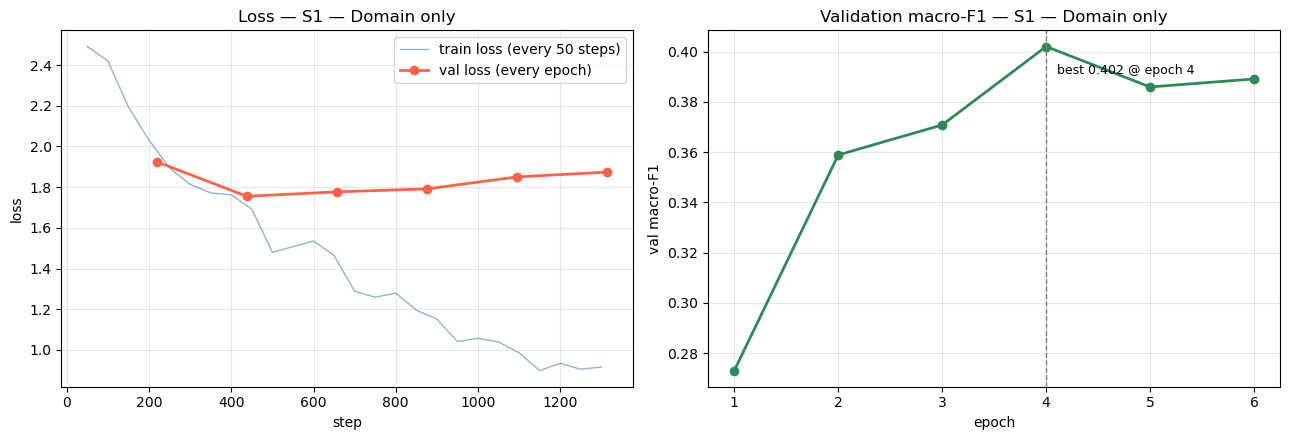

Stopped at epoch 6/6 | best epoch 4 (val macro-F1 0.4020)


Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

S1 | macro-F1 = 0.3645 | accuracy = 0.3893

              precision    recall  f1-score   support

   ambiguous       0.26      0.12      0.17       130
   amusement       0.35      0.32      0.33       122
       anger       0.36      0.34      0.35        58
     anxiety       0.37      0.45      0.41       205
      belief       0.31      0.44      0.37       136
   confusion       0.54      0.55      0.55        92
  depression       0.23      0.29      0.26        31
     disgust       0.42      0.44      0.43       192
  excitement       0.48      0.49      0.48       208
    optimism       0.44      0.33      0.38       244
       panic       0.30      0.35      0.32        46
    surprise       0.30      0.36      0.33        36

    accuracy                           0.39      1500
   macro avg       0.36      0.37      0.36      1500
weighted avg       0.39      0.39      0.38      1500

RAM released


In [25]:
trainer_s1 = finetune("S1", domain_train, domain_val, epochs=6, lr=BEST_LR, cw_power=0.5)
plot_training(trainer_s1, "S1 — Domain only")
pred_s1 = evaluate_bert(trainer_s1, domain_test, "S1")
del trainer_s1; cleanup()

## 7. Strategy 2: Sequential transfer

Stage 1 on GoEmotions (= **Model A**), stage 2 continues fine-tuning on StockEmotions.
Evaluate stage 1 **before** running stage 2.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream 

Map:   0%|          | 0/30433 [00:00<?, ? examples/s]

Map:   0%|          | 0/7609 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,1.026769,1.059157,0.610750,0.688921
2,0.869074,0.996645,0.623511,0.688790
3,0.670043,1.022382,0.626611,0.692864


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

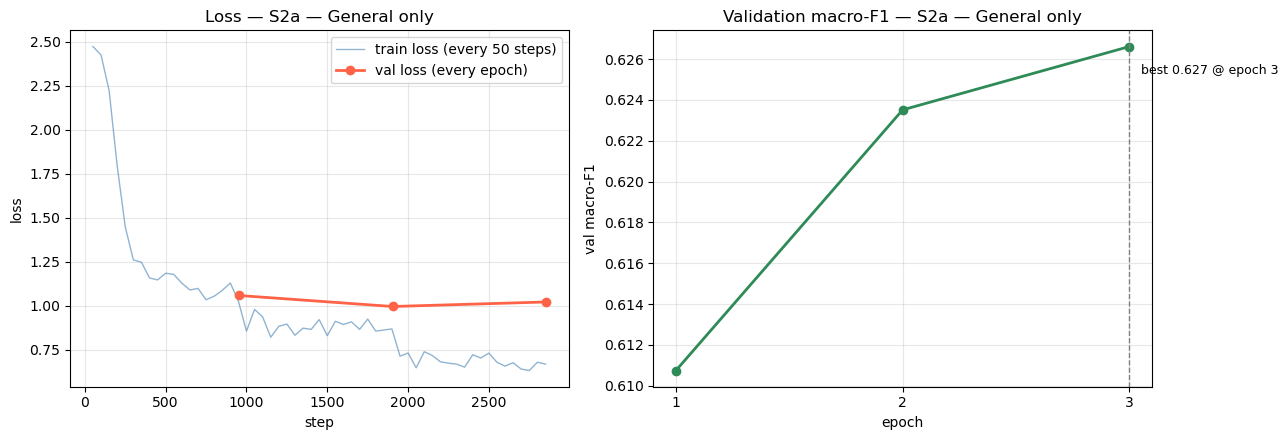

Stopped at epoch 3/3 | best epoch 3 (val macro-F1 0.6266)


Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

S2a | macro-F1 = 0.1387 | accuracy = 0.1680

              precision    recall  f1-score   support

   ambiguous       0.09      0.09      0.09       130
   amusement       0.09      0.08      0.09       122
       anger       0.10      0.31      0.15        58
     anxiety       0.33      0.01      0.02       205
      belief       0.16      0.29      0.21       136
   confusion       0.19      0.37      0.25        92
  depression       0.08      0.26      0.12        31
     disgust       0.17      0.01      0.01       192
  excitement       0.23      0.24      0.24       208
    optimism       0.25      0.29      0.27       244
       panic       0.12      0.04      0.06        46
    surprise       0.15      0.17      0.16        36

    accuracy                           0.17      1500
   macro avg       0.16      0.18      0.14      1500
weighted avg       0.20      0.17      0.14      1500



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

RAM released


In [26]:
trainer_s2a = finetune("S2a", general_train, general_val, epochs=3, lr=BEST_LR, cw_power=0.5)
plot_training(trainer_s2a, "S2a — General only")
pred_A = evaluate_bert(trainer_s2a, domain_test, "S2a")      # = Model A
trainer_s2a.save_model("checkpoints/S2a/best")
del trainer_s2a; cleanup()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Map:   0%|          | 0/7000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,1.911724,1.878250,0.322824,0.348000
2,1.697096,1.771148,0.368102,0.368667
3,1.444456,1.785714,0.375646,0.380667
4,1.142756,1.850924,0.380221,0.377333
5,0.983136,1.922765,0.379948,0.384667
6,0.854135,1.946862,0.383581,0.386667


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

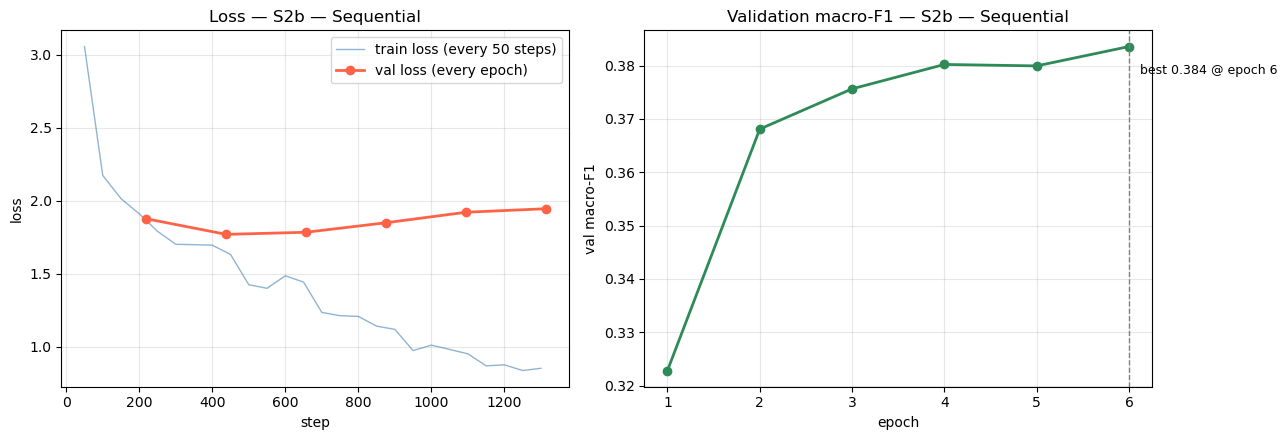

Stopped at epoch 6/6 | best epoch 6 (val macro-F1 0.3836)


Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

S2 | macro-F1 = 0.3528 | accuracy = 0.3753

              precision    recall  f1-score   support

   ambiguous       0.20      0.14      0.16       130
   amusement       0.38      0.39      0.38       122
       anger       0.34      0.45      0.39        58
     anxiety       0.42      0.39      0.40       205
      belief       0.33      0.42      0.37       136
   confusion       0.55      0.50      0.53        92
  depression       0.20      0.19      0.20        31
     disgust       0.40      0.40      0.40       192
  excitement       0.41      0.47      0.44       208
    optimism       0.41      0.34      0.37       244
       panic       0.29      0.33      0.31        46
    surprise       0.25      0.36      0.30        36

    accuracy                           0.38      1500
   macro avg       0.35      0.36      0.35      1500
weighted avg       0.38      0.38      0.37      1500

RAM released


In [27]:
trainer_s2b = finetune("S2b", domain_train, domain_val,
                       init_from="checkpoints/S2a/best", epochs=6, lr=BEST_LR, cw_power=0.5)
plot_training(trainer_s2b, "S2b — Sequential")
pred_s2 = evaluate_bert(trainer_s2b, domain_test, "S2")
del trainer_s2b; cleanup()

## 8. Strategy 3: Mixed  (= Model C)

mixed: 37433 | domain share 18.7%


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream 

Map:   0%|          | 0/37433 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,1.222196,1.868217,0.254410,0.348667
2,1.034570,1.727929,0.328934,0.387333
3,0.865159,1.744906,0.345375,0.394000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

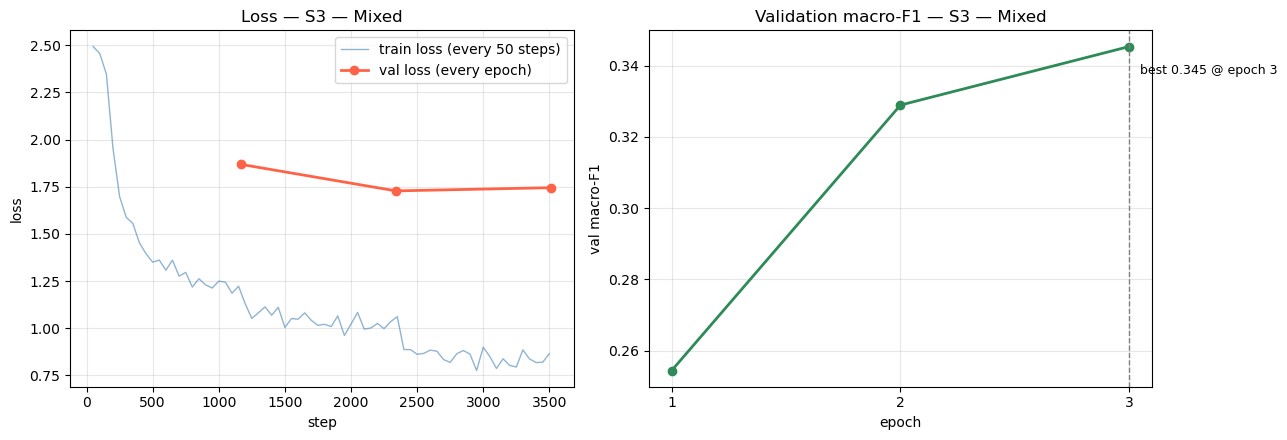

Stopped at epoch 3/3 | best epoch 3 (val macro-F1 0.3454)


Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

S3 | macro-F1 = 0.3564 | accuracy = 0.4047

              precision    recall  f1-score   support

   ambiguous       0.24      0.13      0.17       130
   amusement       0.38      0.30      0.33       122
       anger       0.56      0.16      0.24        58
     anxiety       0.37      0.61      0.46       205
      belief       0.36      0.10      0.15       136
   confusion       0.73      0.43      0.54        92
  depression       0.38      0.26      0.31        31
     disgust       0.39      0.57      0.46       192
  excitement       0.48      0.52      0.50       208
    optimism       0.42      0.45      0.43       244
       panic       0.28      0.37      0.32        46
    surprise       0.33      0.36      0.35        36

    accuracy                           0.40      1500
   macro avg       0.41      0.35      0.36      1500
weighted avg       0.41      0.40      0.39      1500

RAM released


In [28]:
mixed_train = pd.concat([general_train[["text","label"]],
                         domain_train[["text","label"]]], ignore_index=True)
print("mixed:", len(mixed_train), "| domain share", f"{len(domain_train)/len(mixed_train)*100:.1f}%")

trainer_s3 = finetune("S3", mixed_train, domain_val, epochs=3, lr=BEST_LR, cw_power=0.5)
plot_training(trainer_s3, "S3 — Mixed")
pred_s3 = evaluate_bert(trainer_s3, domain_test, "S3")
del trainer_s3; cleanup()

## 9. Summary table + confusion matrix

In [29]:
y = domain_test["label"]
rows = [("A  — General only (S2a)",  len(general_train), pred_A),
        ("B  — Domain only (S1)",    len(domain_train),  pred_s1),
        ("C  — Mixed (S3)",          len(mixed_train),   pred_s3),
        ("S2 — Sequential transfer", len(domain_train),  pred_s2)]

summary = pd.DataFrame([{"strategy": n, "train_size": sz,
                         "macro_f1": f1_score(y, p, average="macro", zero_division=0),
                         "accuracy": accuracy_score(y, p)} for n, sz, p in rows]).round(4)
print(summary.to_string(index=False))
summary.to_csv("results/summary_bert.csv", index=False)

                strategy  train_size  macro_f1  accuracy
 A  — General only (S2a)       30433    0.1387    0.1680
   B  — Domain only (S1)        7000    0.3645    0.3893
         C  — Mixed (S3)       37433    0.3564    0.4047
S2 — Sequential transfer        7000    0.3528    0.3753


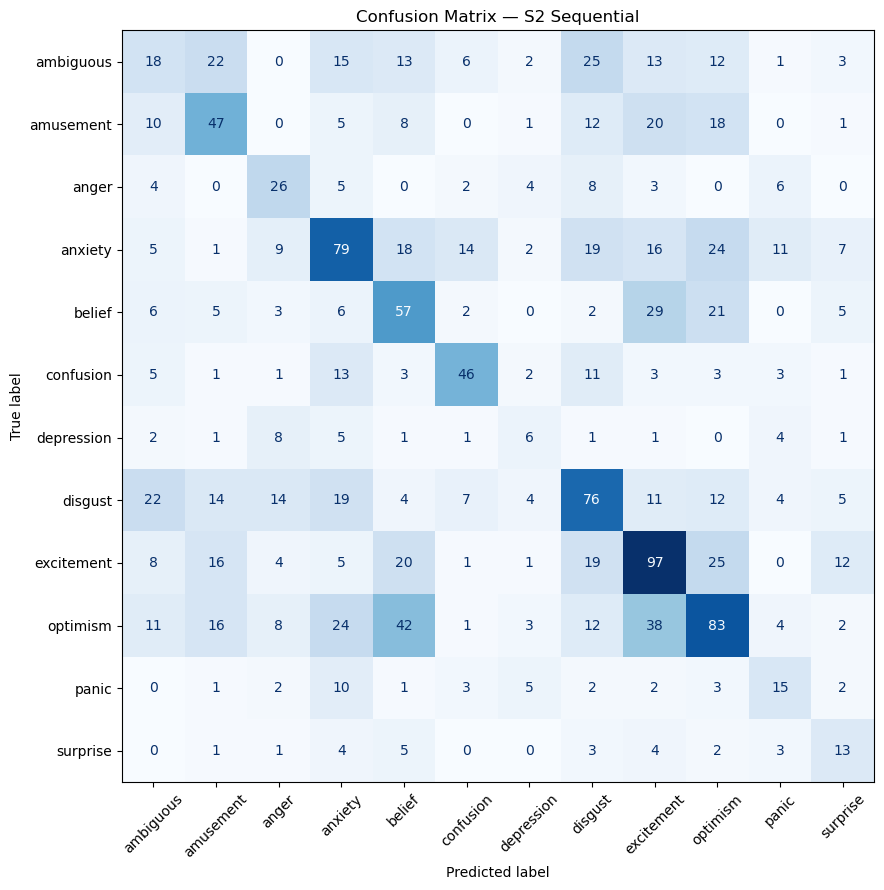

In [30]:
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay.from_predictions(y, pred_s2, xticks_rotation=45, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Confusion Matrix — S2 Sequential")
plt.tight_layout(); plt.show()

## 10. Extensions

Only run these after the three main strategies are complete.

In [31]:
# Seed ensemble: average logits across 3 seeds
for s in [1, 2]:
    t = finetune(f"S1_seed{s}", domain_train, domain_val, epochs=6, lr=BEST_LR, cw_power=0.5, run_seed=s)
    evaluate_bert(t, domain_test, f"S1_seed{s}")
    del t; cleanup()

y = domain_test["label"]
logits   = np.mean([np.load(f"results/logits_{n}.npy") for n in ["S1", "S1_seed1", "S1_seed2"]], axis=0)
pred_ens = [id2label[i] for i in logits.argmax(-1)]
print(f"ENSEMBLE 3 seed | macro-F1 = {f1_score(y, pred_ens, average='macro', zero_division=0):.4f} "f"| accuracy = {accuracy_score(y, pred_ens):.4f}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream 

Map:   0%|          | 0/7000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,2.010204,1.889305,0.307790,0.368667
2,1.687485,1.739063,0.384884,0.402667
3,1.434412,1.735087,0.396821,0.400000
4,1.191168,1.784991,0.401278,0.406667
5,0.984605,1.867929,0.400880,0.406000
6,0.838235,1.904357,0.402877,0.408000


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

S1_seed2 | macro-F1 = 0.3553 | accuracy = 0.3833

              precision    recall  f1-score   support

   ambiguous       0.23      0.21      0.22       130
   amusement       0.36      0.17      0.23       122
       anger       0.28      0.45      0.35        58
     anxiety       0.39      0.43      0.41       205
      belief       0.39      0.38      0.38       136
   confusion       0.52      0.54      0.53        92
  depression       0.25      0.26      0.25        31
     disgust       0.40      0.44      0.42       192
  excitement       0.50      0.51      0.50       208
    optimism       0.43      0.32      0.37       244
       panic       0.23      0.41      0.30        46
    surprise       0.23      0.39      0.29        36

    accuracy                           0.38      1500
   macro avg       0.35      0.38      0.36      1500
weighted avg       0.39      0.38      0.38      1500

RAM released
ENSEMBLE 3 seed | macro-F1 = 0.3775 | accuracy = 0.4047


In [32]:
# Mean pooling instead of [CLS]
t = finetune("S1_mean", domain_train, domain_val, pooling="mean", epochs=6, lr=BEST_LR, cw_power=0.5)
pred_mean = evaluate_bert(t, domain_test, "S1_mean")
del t; cleanup()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: cardiffnlp/twitter-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.decoder.bias      | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Map:   0%|          | 0/7000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,1.975104,1.861721,0.325667,0.366667
2,1.689796,1.720862,0.385173,0.393333
3,1.349424,1.732802,0.377912,0.389333
4,1.050669,1.828609,0.385025,0.391333


Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

S1_mean | macro-F1 = 0.3661 | accuracy = 0.3813

              precision    recall  f1-score   support

   ambiguous       0.25      0.23      0.24       130
   amusement       0.31      0.39      0.34       122
       anger       0.36      0.31      0.33        58
     anxiety       0.44      0.35      0.39       205
      belief       0.34      0.37      0.35       136
   confusion       0.59      0.50      0.54        92
  depression       0.34      0.32      0.33        31
     disgust       0.44      0.35      0.39       192
  excitement       0.51      0.44      0.47       208
    optimism       0.41      0.41      0.41       244
       panic       0.23      0.43      0.30        46
    surprise       0.20      0.47      0.28        36

    accuracy                           0.38      1500
   macro avg       0.37      0.38      0.37      1500
weighted avg       0.40      0.38      0.39      1500

RAM released


## 11. Maximising performance (12-class task)

Each technique below is both an assignment deliverable **and** an extra member for the final
ensemble — more diverse training data means more diverse errors, which is what ensembling exploits.

Run order: longer S1 -> dataset weighting -> domain tags -> DAPT -> ensemble.

### 11.1 Transfer technique — dataset weighting

In the plain mixed set the target domain is only 18.7% of the data, so its signal is diluted.
Oversampling it 3x raises the share to ~41%.

mixed_weighted: 44433 | domain share: 31.5%


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream 

Map:   0%|          | 0/44433 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,1.564946,1.965072,0.289612,0.368667
2,1.357497,1.947042,0.360667,0.394000
3,1.174792,2.027520,0.381486,0.400000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

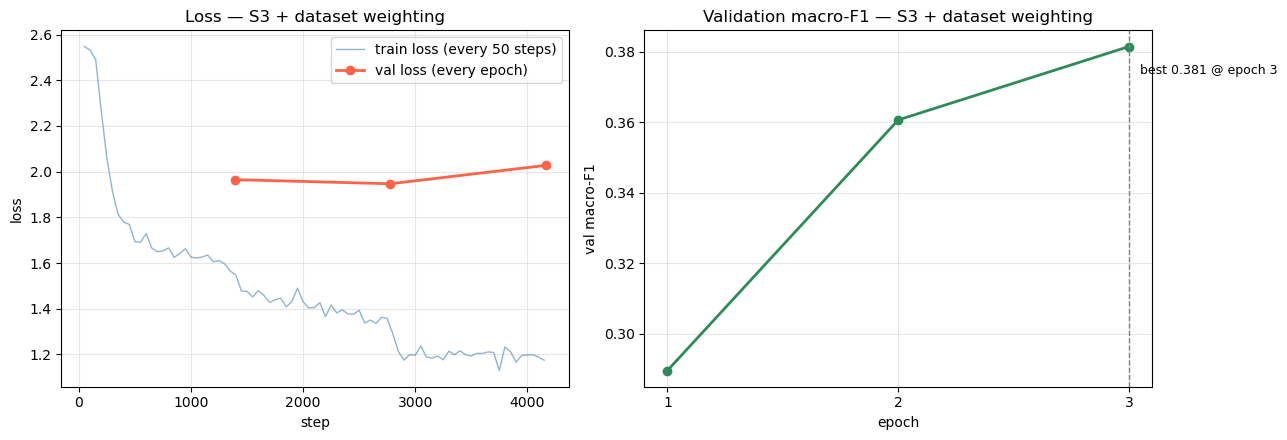

Stopped at epoch 3/3 | best epoch 3 (val macro-F1 0.3815)


Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

S3_weighted | macro-F1 = 0.3710 | accuracy = 0.4053

              precision    recall  f1-score   support

   ambiguous       0.22      0.20      0.21       130
   amusement       0.40      0.37      0.38       122
       anger       0.47      0.33      0.39        58
     anxiety       0.39      0.46      0.42       205
      belief       0.36      0.21      0.27       136
   confusion       0.59      0.46      0.52        92
  depression       0.30      0.19      0.24        31
     disgust       0.45      0.55      0.49       192
  excitement       0.46      0.51      0.49       208
    optimism       0.43      0.43      0.43       244
       panic       0.32      0.41      0.36        46
    surprise       0.23      0.31      0.26        36

    accuracy                           0.41      1500
   macro avg       0.39      0.37      0.37      1500
weighted avg       0.41      0.41      0.40      1500



Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

RAM released


In [15]:
mixed_weighted = pd.concat([general_train[["text","label"]]] +
                           [domain_train[["text","label"]]] * 2, ignore_index=True)
print("mixed_weighted:", len(mixed_weighted),
      "| domain share:", f"{2*len(domain_train)/len(mixed_weighted)*100:.1f}%")

trainer_s3w = finetune("S3_weighted", mixed_weighted, domain_val,
                       epochs=3, lr=BEST_LR, cw_power=0.5)
plot_training(trainer_s3w, "S3 + dataset weighting")
pred_s3w = evaluate_bert(trainer_s3w, domain_test, "S3_weighted", val_df=domain_val)
del trainer_s3w; cleanup()

### 11.2 Transfer technique — domain tags

Prefixing each example with its origin lets the model condition on the domain instead of
being pulled towards the larger source distribution.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream 

Map:   0%|          | 0/37433 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,1.579110,2.030334,0.258902,0.355333
2,1.437524,1.881856,0.342269,0.390000
3,1.313575,1.906159,0.355066,0.382000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

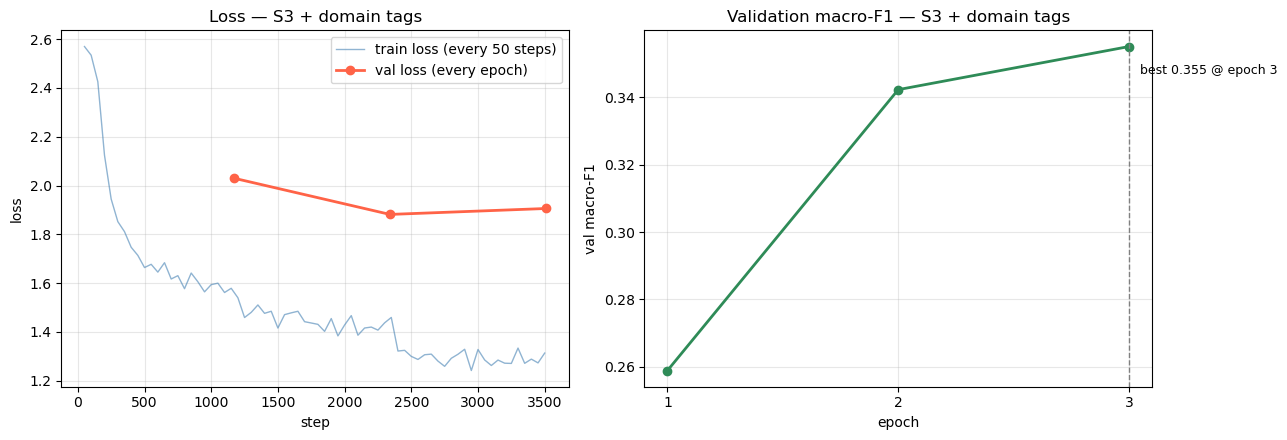

Stopped at epoch 3/3 | best epoch 3 (val macro-F1 0.3551)


Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

S3_tagged | macro-F1 = 0.3612 | accuracy = 0.4033

              precision    recall  f1-score   support

   ambiguous       0.20      0.15      0.17       130
   amusement       0.39      0.30      0.34       122
       anger       0.44      0.21      0.28        58
     anxiety       0.39      0.56      0.46       205
      belief       0.44      0.11      0.18       136
   confusion       0.65      0.43      0.52        92
  depression       0.35      0.26      0.30        31
     disgust       0.40      0.57      0.47       192
  excitement       0.48      0.52      0.50       208
    optimism       0.42      0.45      0.43       244
       panic       0.29      0.33      0.31        46
    surprise       0.33      0.44      0.38        36

    accuracy                           0.40      1500
   macro avg       0.40      0.36      0.36      1500
weighted avg       0.41      0.40      0.39      1500



Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

RAM released


In [16]:
gen_tag  = general_train[["text","label"]].assign(text=lambda d: "[GENERAL] " + d["text"])
dom_tag  = domain_train[["text","label"]].assign(text=lambda d: "[FINANCE] " + d["text"])
mixed_tag = pd.concat([gen_tag, dom_tag], ignore_index=True)

val_tag  = domain_val.assign(text="[FINANCE] "  + domain_val["text"])
test_tag = domain_test.assign(text="[FINANCE] " + domain_test["text"])

trainer_tag = finetune("S3_tagged", mixed_tag, val_tag, epochs=3, lr=BEST_LR, cw_power=0.5)
plot_training(trainer_tag, "S3 + domain tags")
pred_tag = evaluate_bert(trainer_tag, test_tag, "S3_tagged", val_df=val_tag)
del trainer_tag; cleanup()

### 11.3 Recover validation logits for earlier models


In [ ]:
# Recover validation logits for models trained before evaluate_bert saved them.
# Reloads each checkpoint and predicts on domain_val - no re-training needed (~30s each).
import glob, os

CKPT = {"S1":"checkpoints/S1", "S2":"checkpoints/S2b", "S3":"checkpoints/S3", "S2a":"checkpoints/S2a", "S1_seed1":"checkpoints/S1_seed1", "S1_seed2":"checkpoints/S1_seed2"}      # S1_mean uses a custom class -> skipped

for name, folder in CKPT.items():
    out_path = f"results/vallogits_{name}.npy"
    if os.path.exists(out_path):
        print(f"  {name}: already present"); continue
    ck = sorted(glob.glob(f"{folder}/checkpoint-*"), key=lambda p: int(p.rsplit("-", 1)[1]))
    if not ck:
        print(f"  {name}: no checkpoint found"); continue
    m = AutoModelForSequenceClassification.from_pretrained(ck[-1])
    tr = Trainer(model=m, processing_class=tokenizer, args=TrainingArguments(output_dir="tmp_pred", per_device_eval_batch_size=64, report_to="none", dataloader_pin_memory=False))
    np.save(out_path, tr.predict(to_dataset(domain_val)).predictions)
    print(f"  {name}: saved")
    del m, tr; cleanup()


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

  S1: saved
RAM released


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

...

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

  S1_seed1: saved
RAM released


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

  S1_seed2: saved
RAM released


### 11.4 Ensemble + prior calibration

Averaging **softmax** (not raw logits) across models trained on different data.
The calibration exponent `t` is tuned on `domain_val` — never on `domain_test`.

In [ ]:
import glob, os
from scipy.special import softmax

names = sorted(os.path.basename(f)[7:-4] for f in glob.glob("results/logits_*.npy"))
print("Ensemble members:", names)

P_test = np.mean([softmax(np.load(f"results/logits_{n}.npy"), axis=1) for n in names], axis=0)
y_test = domain_test["label"]

# --- tune t on validation, using only members that have val logits ---
val_names = [n for n in names if os.path.exists(f"results/vallogits_{n}.npy")]
prior = domain_train["label"].value_counts(normalize=True).reindex(labels).values

if val_names:
    P_val = np.mean([softmax(np.load(f"results/vallogits_{n}.npy"), axis=1) for n in val_names], axis=0)
    y_val = domain_val["label"]
    grid = []
    for t in np.arange(0, 1.01, 0.25):
        pv = [id2label[i] for i in (P_val * (prior ** t)).argmax(-1)]
        grid.append((t, f1_score(y_val, pv, average="macro", zero_division=0), accuracy_score(y_val, pv)))
    print(pd.DataFrame(grid, columns=["t", "val_macro_f1", "val_accuracy"]).round(4).to_string(index=False))
    BEST_T = max(grid, key=lambda r: r[1])[0]
else:
    BEST_T = 0.0
    print("No validation logits yet -> no calibration (t = 0). Re-run section 11 cells so val logits get saved.")
print("Selected t =", BEST_T)

for tag, pr in [("ensemble (no calibration)", P_test), (f"ensemble + calibration t={BEST_T}", P_test * (prior ** BEST_T))]:
    p = [id2label[i] for i in pr.argmax(-1)]
    print(f"{tag:34s} macro-F1={f1_score(y_test, p, average='macro', zero_division=0):.4f} " 
          f"| accuracy={accuracy_score(y_test, p):.4f}")

pred_ensemble = [id2label[i] for i in (P_test * (prior ** BEST_T)).argmax(-1)]

Ensemble members: ['S1', 'S1_long', 'S1_mean', 'S1_seed1', 'S1_seed2', 'S2', 'S2a', 'S3', 'S3_tagged', 'S3_weighted']
   t  val_macro_f1  val_accuracy
0.00        0.4063        0.4187
0.25        0.4047        0.4207
0.50        0.3977        0.4180
0.75        0.3846        0.4140
1.00        0.3715        0.4107
Selected t = 0.0
  ensemble (no calibration)          macro-F1=0.3968 | accuracy=0.4287
  ensemble + calibration t=0.0       macro-F1=0.3968 | accuracy=0.4287


### 11.5 Final comparison and top-k analysis

In [17]:
import glob, os
rows = []
for f in sorted(glob.glob("results/pred_*.csv")):
    n = os.path.basename(f)[5:-4]
    p = pd.read_csv(f)["pred"]
    rows.append({"model": n,
                 "macro_f1": f1_score(y_test, p, average="macro", zero_division=0),
                 "accuracy": accuracy_score(y_test, p)})
rows.append({"model": "ENSEMBLE",
             "macro_f1": f1_score(y_test, pred_ensemble, average="macro", zero_division=0),
             "accuracy": accuracy_score(y_test, pred_ensemble)})
final = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).round(4)
print(final.to_string(index=False))
final.to_csv("results/final_comparison.csv", index=False)

      model  macro_f1  accuracy
   ENSEMBLE    0.3968    0.4287
S3_weighted    0.3710    0.4053
    S1_mean    0.3661    0.3813
   S1_seed1    0.3647    0.3900
         S1    0.3645    0.3893
  S3_tagged    0.3612    0.4033
         S3    0.3564    0.4047
   S1_seed2    0.3553    0.3833
         S2    0.3528    0.3753
    S1_long    0.3491    0.3720
        S2a    0.1387    0.1680


In [ ]:
# Top-k accuracy: does the model get the right emotion *region* even when top-1 is wrong?
order = np.argsort(-P_test, axis=1)
yi = y_test.map(label2id).values
print("Top-k accuracy (ensemble):")
for k in [1, 2, 3, 5]:
    print(f"  top-{k}: {np.mean([yi[i] in order[i, :k] for i in range(len(yi))]):.4f}")

print("\nMost confused pairs:")
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, pred_ensemble, labels=labels)
pairs = [(cm[i, j], labels[i], labels[j]) for i in range(len(labels)) for j in range(len(labels)) if i != j and cm[i, j] > 0]
for n, a, b in sorted(pairs, reverse=True)[:10]:
    print(f"  {n:4d}  true={a:11s} -> pred={b}")

Top-k accuracy (ensemble):
  top-1: 0.4287
  top-2: 0.6353
  top-3: 0.7487
  top-5: 0.8907

Most confused pairs:
    33  true=optimism    -> pred=excitement
    31  true=optimism    -> pred=anxiety
    28  true=belief      -> pred=excitement
    27  true=ambiguous   -> pred=disgust
    26  true=optimism    -> pred=belief
    26  true=disgust     -> pred=anxiety
    24  true=excitement  -> pred=optimism
    24  true=anxiety     -> pred=optimism
    24  true=amusement   -> pred=optimism
    23  true=excitement  -> pred=disgust


## 12. Overfitting mitigation - ablation

Diagnosis from the completed runs: at 6 epochs, every domain-only model ends with
train_loss well below val_loss (gap up to 1.09) and val_loss rising 10% past its minimum,
while macro-F1 keeps climbing — the checkpoint selector was keeping an over-confident model.
S1 (no mitigation) scored macro-F1 = 0.3645 on `domain_test`.

Each lever is isolated against that S1 baseline, then combined. ~35-40 min total on a
healthy machine (swap low, `caffeinate -dis` running) — run one cell block, let it finish,
then move to the next rather than queuing everything at once.

In [ ]:
baseline_f1 = f1_score(domain_test["label"], pd.read_csv("results/pred_S1.csv")["pred"], average="macro", zero_division=0)
print(f"Baseline (S1, no mitigation): macro-F1 = {baseline_f1:.4f}")

ablation_configs = {
    "1_epoch_cap": dict(epochs=4),                     # lever 1: fewer epochs
    "2_select_loss": dict(select_by="loss"),              # levers 2+6: pick checkpoint by val_loss
    "3_weight_decay": dict(weight_decay=0.05),              # lever 3: stronger L2
    "4_freeze8": dict(freeze_layers=8),                # lever 4: freeze bottom 8/12 layers
    "5_dropout03": dict(dropout=0.3),                    # lever 5: higher dropout
    "6_combined": dict(epochs=4, select_by="loss", weight_decay=0.05, freeze_layers=8, dropout=0.3),   # all six together
}

### Run each lever (sequential — watch RAM between runs)

In [ ]:
import os
ablation_results = []
for tag, overrides in ablation_configs.items():
    if os.path.exists(f"results/pred_S1_abl_{tag}.csv"):        # resume-safe: skip finished levers
        print(f"=== {tag}: already done, skipping ===")
        d = pd.read_csv(f"results/pred_S1_abl_{tag}.csv")
        ablation_results.append({
            "lever": tag, **{k: str(v) for k, v in overrides.items()},
            "macro_f1": f1_score(d["true"], d["pred"], average="macro", zero_division=0),
            "accuracy": accuracy_score(d["true"], d["pred"])})
        continue

    kw = dict(epochs=6, lr=BEST_LR, cw_power=0.5, patience=2)   # S1-matching defaults
    kw.update(overrides)
    print(f"\n=== {tag}  {overrides} ===")

    t = finetune(f"S1_abl_{tag}", domain_train, domain_val, **kw)
    plot_training(t, f"S1 — {tag}")
    pred = evaluate_bert(t, domain_test, f"S1_abl_{tag}", val_df=domain_val)

    ablation_results.append({
        "lever": tag, **{k: str(v) for k, v in overrides.items()},
        "macro_f1": f1_score(domain_test["label"], pred, average="macro", zero_division=0),
        "accuracy": accuracy_score(domain_test["label"], pred)})
    del t; cleanup()

### Summary

In [ ]:
ablation_df = pd.DataFrame(ablation_results)
ablation_df["delta_vs_baseline"] = (ablation_df["macro_f1"] - baseline_f1).round(4)
print(f"\nBaseline (no mitigation): macro-F1 = {baseline_f1:.4f}\n")
print(ablation_df[["lever", "macro_f1", "accuracy", "delta_vs_baseline"]].round(4).to_string(index=False))
ablation_df.to_csv("results/ablation_overfitting.csv", index=False)

best = ablation_df.loc[ablation_df["macro_f1"].idxmax()]
print(f"\nBest lever: {best['lever']}  (macro-F1 = {best['macro_f1']:.4f}, "
      f"{'+' if best['delta_vs_baseline']>=0 else ''}{best['delta_vs_baseline']:.4f} vs baseline)")

## 13. LoRA - parameter-efficient fine-tuning

Targets the actual root cause of the overfitting seen throughout Section 12: roberta-base
has ~125M parameters against only 7,000 domain_train examples (~17,857 params/sample).
LoRA freezes the whole base model and trains small rank-decomposition adapters on the
query/value projections instead -- about 0.7% of parameters.

Verified separately: saves/reloads correctly via `trainer.save_model()`
(`adapter_model.safetensors` + `adapter_config.json`, not a full checkpoint), and
`PeftModel.from_pretrained(base_model, path)` reloads it for later use. LoRA typically
wants a **higher** learning rate (~1e-4) than full fine-tuning (~3e-5), since only the
small adapter matrices are being updated.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream 

trainable params: 894,732 || all params: 125,549,592 || trainable%: 0.7127


Map:   0%|          | 0/7000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,2.509154,2.453304,0.117722,0.238667
2,2.148393,2.088256,0.326753,0.343333
3,2.072574,2.032731,0.358456,0.375333
4,1.984754,2.014446,0.361697,0.374000
5,1.983746,2.015373,0.368020,0.382000
6,1.960159,1.995422,0.380320,0.394000
7,1.929081,1.980152,0.389831,0.397333
8,1.932035,1.988291,0.390630,0.399333
9,1.886660,1.987611,0.385134,0.392667
10,1.918679,1.982027,0.384313,0.392667


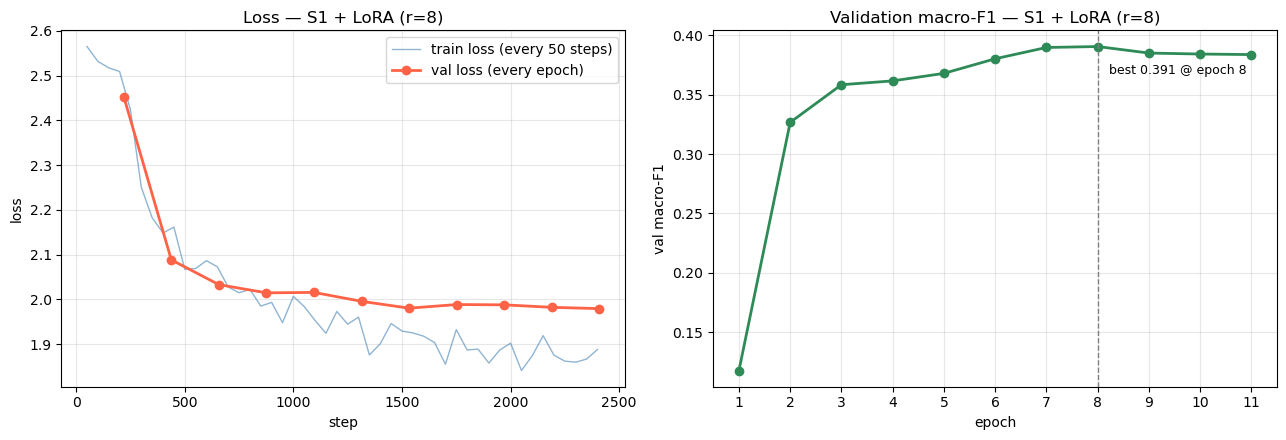

Stopped at epoch 11/12 | best epoch 8 (val macro-F1 0.3906)


Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

S1_lora | macro-F1 = 0.3648 | accuracy = 0.3893

              precision    recall  f1-score   support

   ambiguous       0.30      0.17      0.22       130
   amusement       0.39      0.41      0.40       122
       anger       0.28      0.36      0.32        58
     anxiety       0.47      0.29      0.36       205
      belief       0.33      0.31      0.32       136
   confusion       0.50      0.53      0.52        92
  depression       0.23      0.39      0.29        31
     disgust       0.43      0.54      0.48       192
  excitement       0.43      0.53      0.48       208
    optimism       0.42      0.34      0.38       244
       panic       0.22      0.37      0.28        46
    surprise       0.30      0.44      0.36        36

    accuracy                           0.39      1500
   macro avg       0.36      0.39      0.36      1500
weighted avg       0.40      0.39      0.38      1500



Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

RAM released


In [14]:
trainer_lora = finetune("S1_lora", domain_train, domain_val,
                        use_lora=True, lora_r=8, lora_alpha=16, lora_dropout=0.1,
                        epochs=12, patience=3, lr=1e-4, cw_power=0.5)
plot_training(trainer_lora, "S1 + LoRA (r=8)")
pred_lora = evaluate_bert(trainer_lora, domain_test, "S1_lora", val_df=domain_val)
del trainer_lora; cleanup()

### Compare against the S1 baseline (no LoRA, full fine-tune, same domain_train)

In [15]:
baseline_f1 = f1_score(domain_test["label"], pd.read_csv("results/pred_S1.csv")["pred"],
                       average="macro", zero_division=0)
lora_f1 = f1_score(domain_test["label"], pred_lora, average="macro", zero_division=0)
lora_acc = accuracy_score(domain_test["label"], pred_lora)
print(f"S1 (full fine-tune): macro-F1 = {baseline_f1:.4f}")
print(f"S1_lora (LoRA)     : macro-F1 = {lora_f1:.4f}  accuracy = {lora_acc:.4f}  "
      f"(delta {lora_f1 - baseline_f1:+.4f})")

S1 (full fine-tune): macro-F1 = 0.3645
S1_lora (LoRA)     : macro-F1 = 0.3648  accuracy = 0.3893  (delta +0.0004)


## 14. Combined technique stack (12-class ceiling check)

Every technique so far was tested **in isolation**: dataset weighting alone, domain tags
alone, LoRA alone. None pushed macro-F1 past ~0.39. This section stacks the three that
individually helped (dataset weighting + domain tags + LoRA) into one run, as the final
attempt to raise the 12-class ceiling before concluding it is a label-granularity problem
rather than a training-recipe problem.

In [ ]:
gen_tag_w = general_train[["text","label"]].assign(text=lambda d: "[GENERAL] " + d["text"])
dom_tag_w = (pd.concat([domain_train[["text","label"]]] * 2, ignore_index=True)
            .assign(text=lambda d: "[FINANCE] " + d["text"]))
mixed_tag_weighted = pd.concat([gen_tag_w, dom_tag_w], ignore_index=True)

val_tag_c  = domain_val.assign(text="[FINANCE] "  + domain_val["text"])
test_tag_c = domain_test.assign(text="[FINANCE] " + domain_test["text"])

print("mixed_tag_weighted:", len(mixed_tag_weighted),
      "| domain share:", f"{2*len(domain_train)/len(mixed_tag_weighted)*100:.1f}%")

trainer_combined = finetune("S_combined", mixed_tag_weighted, val_tag_c,
                            use_lora=True, lora_r=16, lora_alpha=32, lora_dropout=0.1,
                            epochs=10, patience=3, lr=1e-4, cw_power=0.5)
plot_training(trainer_combined, "Combined: weighting + tags + LoRA")
pred_combined = evaluate_bert(trainer_combined, test_tag_c, "S_combined", val_df=val_tag_c)
del trainer_combined; cleanup()

### Updated ensemble (all models, including the combined run)

In [ ]:
import glob, os
from scipy.special import softmax

names = sorted(os.path.basename(f)[7:-4] for f in glob.glob("results/logits_*.npy"))
print("Ensemble members:", names)

P_all = np.mean([softmax(np.load(f"results/logits_{n}.npy"), axis=1) for n in names], axis=0)
pred_all = [id2label[i] for i in P_all.argmax(-1)]

f1_combined = f1_score(domain_test["label"], pred_combined, average="macro", zero_division=0)
f1_ensemble_all = f1_score(domain_test["label"], pred_all, average="macro", zero_division=0)
print(f"S_combined (single model)      : macro-F1 = {f1_combined:.4f}")
print(f"Ensemble (all models, incl. it): macro-F1 = {f1_ensemble_all:.4f}  "
      f"accuracy = {accuracy_score(domain_test['label'], pred_all):.4f}")
print(f"\nCeiling after every technique tried (isolated + combined): ~{max(f1_combined, f1_ensemble_all):.2f} macro-F1")

## 15. Binary sentiment - reduced label granularity

Section 14 showed that stacking every technique that worked individually still caps out
well short of 0.5 macro-F1 on the 12-class task. This section repeats the same A/B/C
framework (general-only / domain-only / mixed) on a **binary** sentiment label space —
GoEmotions' official positive/negative grouping for the source, StockEmotions'
`senti_label` (bullish/bearish) for the target — to test whether the ceiling is a
training-recipe problem or a label-granularity problem.

Reuses `finetune()` / `evaluate_bert()` unchanged via the `label_space=` parameter added
above; the 12-class globals (`labels`, `label2id`, `id2label`) are untouched.

### 15.1 Data and label mapping

In [ ]:
POSITIVE = ["admiration","amusement","approval","caring","desire","excitement", "gratitude","joy","love","optimism","pride","relief"]
NEGATIVE = ["anger","annoyance","disappointment","disapproval","disgust","embarrassment", "fear","grief","nervousness","remorse","sadness"]
# confusion/curiosity/realization/surprise/ambiguous/neutral have no clear positive/negative
# polarity and are dropped for this binary task (they were already excluded or merged
# differently in the 12-class mapping).
senti_map = {**{e: "positive" for e in POSITIVE}, **{e: "negative" for e in NEGATIVE}}

general_raw_bin = pd.read_csv("data/general_clean.csv")
general_bin = general_raw_bin.copy()
general_bin["label"] = general_bin["label"].map(senti_map)
general_bin = general_bin.dropna(subset=["label"]).reset_index(drop=True)

domain_raw_bin = pd.read_csv("data/domain_clean.csv")
domain_bin = domain_raw_bin[["text", "senti_label"]].rename(columns={"senti_label": "label"})
domain_bin["label"] = domain_bin["label"].map({"bullish": "positive", "bearish": "negative"})

labels_bin   = sorted(domain_bin["label"].unique())
label2id_bin = {l: i for i, l in enumerate(labels_bin)}
id2label_bin = {i: l for l, i in label2id_bin.items()}
LABEL_SPACE_BIN = (labels_bin, label2id_bin, id2label_bin)

print(f"general_bin: {len(general_bin)} rows | domain_bin: {len(domain_bin)} rows | {len(labels_bin)} labels")
print(general_bin["label"].value_counts().to_string())
print(domain_bin["label"].value_counts().to_string())

In [ ]:
general_train_bin, general_val_bin = train_test_split(general_bin, test_size=.2, stratify=general_bin["label"], random_state=seed)
domain_train_bin, domain_rest_bin = train_test_split(domain_bin, test_size=.3, stratify=domain_bin["label"], random_state=seed)
domain_val_bin, domain_test_bin = train_test_split(domain_rest_bin, test_size=.5, stratify=domain_rest_bin["label"], random_state=seed)

print(f"general_bin {len(general_train_bin)}/{len(general_val_bin)} | domain_bin {len(domain_train_bin)}/{len(domain_val_bin)}/{len(domain_test_bin)}")

### 15.2 Strategy B - domain only

In [ ]:
trainer_b1 = finetune("B1_bin", domain_train_bin, domain_val_bin, epochs=6, lr=BEST_LR, cw_power=0.5, label_space=LABEL_SPACE_BIN)
plot_training(trainer_b1, "Binary — domain only")
pred_b1_bin = evaluate_bert(trainer_b1, domain_test_bin, "B1_bin", val_df=domain_val_bin, label_space=LABEL_SPACE_BIN)
del trainer_b1; cleanup()

### 15.3 Strategy A/Sequential - general only, then fine-tune on domain

In [ ]:
trainer_a_bin = finetune("A_bin", general_train_bin, general_val_bin, epochs=3, lr=BEST_LR, cw_power=0.5, label_space=LABEL_SPACE_BIN)
plot_training(trainer_a_bin, "Binary — general only")
pred_a_bin = evaluate_bert(trainer_a_bin, domain_test_bin, "A_bin", val_df=domain_val_bin, label_space=LABEL_SPACE_BIN)   # = Model A
trainer_a_bin.save_model("checkpoints/A_bin/best")
del trainer_a_bin; cleanup()

In [ ]:
trainer_seq_bin = finetune("Seq_bin", domain_train_bin, domain_val_bin, init_from="checkpoints/A_bin/best", epochs=6, lr=BEST_LR, cw_power=0.5, label_space=LABEL_SPACE_BIN)
plot_training(trainer_seq_bin, "Binary — sequential transfer")
pred_seq_bin = evaluate_bert(trainer_seq_bin, domain_test_bin, "Seq_bin", val_df=domain_val_bin, label_space=LABEL_SPACE_BIN)
del trainer_seq_bin; cleanup()

### 15.4 Strategy C - mixed

In [ ]:
mixed_bin = pd.concat([general_train_bin[["text","label"]], domain_train_bin[["text","label"]]], ignore_index=True)
trainer_c_bin = finetune("C_bin", mixed_bin, domain_val_bin, epochs=3, lr=BEST_LR, cw_power=0.5, label_space=LABEL_SPACE_BIN)
plot_training(trainer_c_bin, "Binary — mixed")
pred_c_bin = evaluate_bert(trainer_c_bin, domain_test_bin, "C_bin", val_df=domain_val_bin, label_space=LABEL_SPACE_BIN)
del trainer_c_bin; cleanup()

### 15.5 Summary - binary vs 12-class ceiling

In [ ]:
y_bin = domain_test_bin["label"]
rows_bin = [("A: General only", pred_a_bin), ("B   — Domain only", pred_b1_bin),("C: Mixed",        pred_c_bin), ("Seq: Sequential transfer", pred_seq_bin)]
summary_bin = pd.DataFrame([{"strategy": n, "macro_f1": f1_score(y_bin, p, average="macro", zero_division=0), "accuracy": accuracy_score(y_bin, p)} for n, p in rows_bin]).round(4)
print("=== Binary sentiment (positive/negative) ===")
print(summary_bin.to_string(index=False))
summary_bin.to_csv("results/summary_binary.csv", index=False)

print(f"\n=== 12-class ceiling vs binary floor ===")
print(f"12-class, best single model / combined: ~0.37-0.40 macro-F1")
print(f"12-class, full ensemble: {f1_ensemble_all:.4f} macro-F1")
print(f"Binary, best strategy: {summary_bin['macro_f1'].max():.4f} macro-F1")

## 16. RCNN head (Nguyen et al., arXiv:2011.10426)

Last literature-backed technique tried before concluding the 12-class investigation.
Uses ALL token representations (last 4 hidden layers) through a BiLSTM + Conv1d instead
of just the [CLS] token -- the authors' best variant, +0.25-1 F1 point over plain
BERT-base on their two Vietnamese review datasets.

In [ ]:
trainer_rcnn = finetune("S1_rcnn", domain_train, domain_val, pooling="rcnn", epochs=8, patience=3, lr=BEST_LR, cw_power=0.5)
plot_training(trainer_rcnn, "S1 + RCNN head")
pred_rcnn = evaluate_bert(trainer_rcnn, domain_test, "S1_rcnn", val_df=domain_val)
del trainer_rcnn; cleanup()

### Compare against the S1 baseline (same data, [CLS]-only)

In [ ]:
f1_base = f1_score(domain_test["label"], pd.read_csv("results/pred_S1.csv")["pred"], average="macro", zero_division=0)
f1_rcnn = f1_score(domain_test["label"], pred_rcnn, average="macro", zero_division=0)
acc_rcnn = accuracy_score(domain_test["label"], pred_rcnn)
print(f"S1 ([CLS] baseline): macro-F1 = {f1_base:.4f}")
print(f"S1_rcnn (RCNN head): macro-F1 = {f1_rcnn:.4f}  accuracy = {acc_rcnn:.4f} (delta {f1_rcnn - f1_base:+.4f})")

## 17. Master report table (Sections 6-16)

One row per experiment, in the order it was run through the notebook — the full
narrative from Strategy 1 through the binary-task comparison. Reads directly from
`results/*.csv` + `*.npy`, independent of in-memory state.

In [ ]:
import glob, os
import pandas as pd, numpy as np
from sklearn.metrics import f1_score, accuracy_score
from scipy.special import softmax

def f1acc(path):
    d = pd.read_csv(path)
    return (f1_score(d["true"], d["pred"], average="macro", zero_division=0),
            accuracy_score(d["true"], d["pred"]))

# (section, file suffix, description, task)
ROWS = [
    ("6", "S1","Strategy 1 — Domain only (Model B)","12-class"),
    ("7", "S2a", "Strategy 2a — General only (Model A)", "12-class"),
    ("7", "S2", "Strategy 2b — Sequential transfer", "12-class"),
    ("8", "S3", "Strategy 3 — Mixed (Model C)", "12-class"),
    ("10", "S1_mean", "Extension — Mean pooling", "12-class"),
    ("10", "S1_seed1", "Extension — Seed ensemble (seed 1)", "12-class"),
    ("10", "S1_seed2", "Extension — Seed ensemble (seed 2)", "12-class"),
    ("11.2", "S3_weighted", "Transfer technique — Dataset weighting","12-class"),
    ("11.3", "S3_tagged", "Transfer technique — Domain tags", "12-class"),
    ("12", "S1_long", "Ablation — Longer training (12 ep, no technique)", "12-class"),
    ("12", "S1_abl_1_epoch_cap", "Ablation — Lower epoch cap", "12-class"),
    ("12", "S1_abl_2_select_loss",  "Ablation — Select checkpoint by val_loss","12-class"),
    ("12", "S1_abl_3_weight_decay", "Ablation — Higher weight decay", "12-class"),
    ("13", "S1_lora", "LoRA (parameter-efficient fine-tuning)","12-class"),
    ("14", "S_combined","Combined: weighting + tags + LoRA","12-class"),
    ("17",   "S1_rcnn", "RCNN head (all tokens, BiLSTM+Conv1d)","12-class"),
    ("15.2", "B1_bin", "Binary Strategy B — Domain only","binary"),
    ("15.3", "A_bin", "Binary Strategy A — General only", "binary"),
    ("15.3", "Seq_bin", "Binary — Sequential transfer","binary"),
    ("15.4", "C_bin","Binary Strategy C — Mixed","binary"),
]

rows = []
for sec, suf, desc, task in ROWS:
    path = f"results/pred_{suf}.csv"
    if not os.path.exists(path):
        print("missing:", path); continue
    f1, acc = f1acc(path)
    rows.append({"section": sec, "model": suf, "description": desc, "task": task, "macro_f1": round(f1, 4), "accuracy": round(acc, 4)})

# 12-class ensemble row (computed, not a single prediction file)
truth = pd.read_csv("results/pred_S1.csv")["true"]
labels = sorted(truth.unique()); id2label = {i: l for i, l in enumerate(labels)}
ens_names = sorted(n for n in (os.path.basename(f)[7:-4] for f in glob.glob("results/logits_*.npy")) if "_bin" not in n)
P_ens = np.mean([softmax(np.load(f"results/logits_{n}.npy"), axis=1) for n in ens_names], axis=0)
pred_ens = [id2label[i] for i in P_ens.argmax(-1)]
rows.append({"section": "14", "model": "ENSEMBLE_ALL",
            "description": f"Ensemble of {len(ens_names)} 12-class models",
            "task": "12-class",
            "macro_f1": round(f1_score(truth, pred_ens, average="macro", zero_division=0), 4),
            "accuracy": round(accuracy_score(truth, pred_ens), 4)})

master = pd.DataFrame(rows)
print(master.to_string(index=False))
master.to_csv("results/master_report_table.csv", index=False)
print(f"\nSaved results/master_report_table.csv - {len(master)} rows")